In [48]:
# import numpy as np
# import pandas as pd

# # СГЕНЕРИРУЙТЕ СВОЙ SEED
# MY_SEED = np.random.randint(5000000, size=1)[0]
# np.random.seed(MY_SEED)

# # СГЕНЕРИРУЙТЕ ЧИСЛО УЧАСТНИКОВ ЭКСПЕРИМЕНТА
# n_users = np.random.randint(1000, 10000, size=1)[0]

# # Шаг 1: создаём ковариату pre_activity (логинормальное распределение)
# pre_activity = np.random.exponential(scale=10, size=n_users).astype(int)

# # Шаг 2: НАРУШЕНИЕ 1 — SRM (Sample Ratio Mismatch)
# # Вместо 50/50 делаем 40/60
# variant = np.random.choice(['control', 'test'], size=n_users, p=[0.4, 0.6])

# # Шаг 3: НАРУШЕНИЕ 2 — confounder (рандомизация зависит от pre_activity)
# # Для тестовой группы увеличиваем вероятность назначения для активных пользователей
# # (это нарушает независимость)
# prob_test = 0.4 + 0.3 * (pre_activity / pre_activity.max())
# variant2 = np.where(np.random.random(n_users) < prob_test, 'test', 'control')

# # Комбинируем оба нарушения (можно взять одно из двух, но для задачи оставим оба)
# # Для простоты выберем основное назначение через variant2 (confounder)
# variant = variant2

# # НАРУШЕНИЕ 3 — дисбаланс guardrail (ошибки чаще в тесте)
# # В тесте ошибки встречаются в 2 раза чаще, хотя истинного эффекта нет
# error_flag = np.zeros(n_users)
# error_flag[variant == 'control'] = np.random.binomial(1, 0.01, sum(variant == 'control'))
# error_flag[variant == 'test'] = np.random.binomial(1, 0.02, sum(variant == 'test'))

# # Конверсия не зависит от варианта, но зависит от pre_activity
# conversion_prob = 0.05 + 0.01 * (pre_activity / pre_activity.max())
# converted = np.random.binomial(1, conversion_prob, n_users)

# # Шаг 4: Генерация дат (например, за 14 дней, с возможным смещением)
# start_date = pd.Timestamp('2026-05-01')
# dates = [start_date + pd.Timedelta(days=np.random.randint(0, 14)) for _ in range(n_users)]

# df = pd.DataFrame({
#     'user_id': range(n_users),
#     'variant': variant,
#     'converted': converted,
#     'error_flag': error_flag,
#     'pre_activity': pre_activity,
#     'date': dates})

# df.to_csv('experiment_data.csv', index=False)
# print("Данные сохранены. Идентифицируйте проблемы")

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

df = pd.read_csv('experiment_data.csv')
df['error_flag'] = df['error_flag'].astype(int)

# Простая проверка данных
print("Дубликаты user_id:", df['user_id'].duplicated().sum())
print("Пропуски:", df.isnull().sum().sum())

# Сводка по группам
summary = df.groupby('variant').agg(
    users=('user_id', 'count'),
    conversions=('converted', 'mean'),
    errors=('error_flag', 'mean'),
    avg_pre_activity=('pre_activity', 'mean')
).round(4)
display(summary)

Дубликаты user_id: 0
Пропуски: 0


,users,conversions,errors,avg_pre_activity
variant,,,,
control,1081,0.0537,0.0074,8.3210
test,908,0.0496,0.0209,10.7059


In [50]:
from scipy.stats import chisquare

observed = df['variant'].value_counts().reindex(['control', 'test'], fill_value=0)
expected = [len(df) / 2, len(df) / 2]

chi2_stat, p_value_srm = chisquare(f_obs=observed.values, f_exp=expected)

print(f"Control: {observed['control']} ({observed['control']/len(df)*100:.1f}%)")
print(f"Test: {observed['test']} ({observed['test']/len(df)*100:.1f}%)")
print("p-value:", p_value_srm)

if p_value_srm < 0.05:
    print("ВЫВОД: SRM обнаружен. Соотношение не 50/50, значит рандомизация сломана.")

Control: 1081 (54.3%)
Test: 908 (45.7%)
p-value: 0.00010485236562035019
ВЫВОД: SRM обнаружен. Соотношение не 50/50, значит рандомизация сломана.


Средняя активность control: 8.32
Средняя активность test: 10.71
p-value: 1.2941400651284959e-05
ВЫВОД: Группы отличаются по исходной активности (confounder).


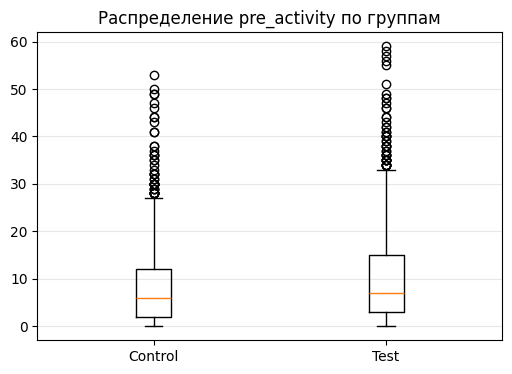

In [51]:
from scipy.stats import mannwhitneyu

control = df[df['variant'] == 'control']['pre_activity']
test = df[df['variant'] == 'test']['pre_activity']

u_stat, p_value_activity = mannwhitneyu(control, test, alternative='two-sided')

print("Средняя активность control:", round(control.mean(), 2))
print("Средняя активность test:", round(test.mean(), 2))
print("p-value:", p_value_activity)

if p_value_activity < 0.05:
    print("ВЫВОД: Группы отличаются по исходной активности (confounder).")

# Простая и понятная картинка
plt.figure(figsize=(6, 4))
plt.boxplot([control, test], tick_labels=['Control', 'Test'])
plt.title('Распределение pre_activity по группам')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [52]:
error_summary = df.groupby('variant').agg(users=('user_id', 'count'), errors=('error_flag', 'sum'))
errors = error_summary.loc[['control', 'test'], 'errors'].values
users = error_summary.loc[['control', 'test'], 'users'].values

z_stat, p_value_errors = proportions_ztest(count=errors, nobs=users)

print(f"Ошибки control: {errors[0]} / {users[0]} = {errors[0]/users[0]*100:.2f}%")
print(f"Ошибки test: {errors[1]} / {users[1]} = {errors[1]/users[1]*100:.2f}%")
print("p-value:", p_value_errors)

if p_value_errors < 0.05:
    print("ВЫВОД: В тестовой группе статистически значимо больше ошибок. Фича технически сломана.")

Ошибки control: 8 / 1081 = 0.74%
Ошибки test: 19 / 908 = 2.09%
p-value: 0.009421752722164044
ВЫВОД: В тестовой группе статистически значимо больше ошибок. Фича технически сломана.


CR control: 58 / 1081 = 5.37%
CR test: 45 / 908 = 4.96%
p-value: 0.6814551415319887
ВЫВОД: Статистически значимой разницы в конверсии нет.


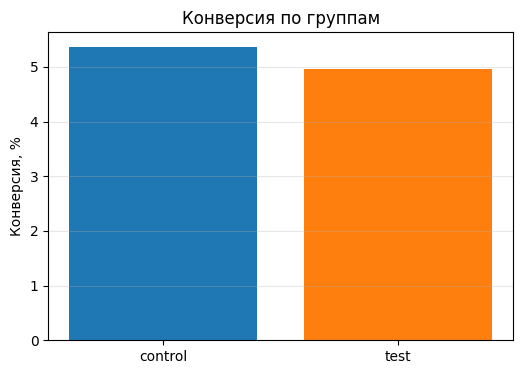

In [53]:
conv_summary = df.groupby('variant').agg(conversions=('converted', 'sum'), users=('converted', 'count'))
conversions = conv_summary.loc[['control', 'test'], 'conversions'].values
users = conv_summary.loc[['control', 'test'], 'users'].values

z_stat_conv, p_value_conv = proportions_ztest(count=conversions, nobs=users)

print(f"CR control: {conversions[0]} / {users[0]} = {conversions[0]/users[0]*100:.2f}%")
print(f"CR test: {conversions[1]} / {users[1]} = {conversions[1]/users[1]*100:.2f}%")
print("p-value:", p_value_conv)

if p_value_conv < 0.05:
    print("ВЫВОД: Разница в конверсии значима.")
else:
    print("ВЫВОД: Статистически значимой разницы в конверсии нет.")

# График
plt.figure(figsize=(6, 4))
rates = df.groupby('variant')['converted'].mean() * 100
plt.bar(rates.index, rates.values, color=['#1f77b4', '#ff7f0e'])
plt.title('Конверсия по группам')
plt.ylabel('Конверсия, %')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [54]:
import statsmodels.formula.api as smf

# Модель без поправки
model_basic = smf.logit('converted ~ C(variant)', data=df).fit(disp=False)
# Модель с поправкой на активность
model_adjusted = smf.logit('converted ~ C(variant) + pre_activity', data=df).fit(disp=False)

print("Коэффициент test (без поправки):", round(model_basic.params['C(variant)[T.test]'], 4))
print("Коэффициент test (с поправкой на pre_activity):", round(model_adjusted.params['C(variant)[T.test]'], 4))
print("\nВ обеих моделях p-value > 0.05. Добавление ковариаты не меняет вывод: значимого эффекта нет.")

Коэффициент test (без поправки): -0.0837
Коэффициент test (с поправкой на pre_activity): -0.1053

В обеих моделях p-value > 0.05. Добавление ковариаты не меняет вывод: значимого эффекта нет.


## Итоговый вывод

Эксперимент **невалиден**, использовать его результаты для принятия решений нельзя.

Обнаружены три критические проблемы:

1. **SRM (Sample Ratio Mismatch)** — пользователи распределились не 50/50: control 54.3% (1081), test 45.7% (908).
   Хи-квадрат: χ² = 15.05, p = 0.000105. Механизм сплитования работает некорректно.

2. **Дисбаланс ковариаты pre_activity** — средняя активность в группах 8.32 (control) против 10.71 (test).
   Критерий Манна — Уитни: p = 0.0000129. Группы изначально неравны, сравнение метрик смещено.
   Обе проблемы (SRM и дисбаланс) вызваны одним дефектом — рандомизация зависит от признака пользователя.

3. **Деградация guardrail-метрики** — частота ошибок выросла с 0.74% (8/1081) до 2.09% (19/908),
   Z = −2.60, p = 0.0094. Тестовая фича технически неисправна.

**Основная метрика (конверсия):** 5.37% (58/1081) в control против 4.96% (45/908) в test,
Z = 0.41, p = 0.68 — статистически значимой разницы нет. Но из-за невалидности эксперимента
этот результат нельзя считать причинно-следственным. Бонусная логистическая регрессия с поправкой
на pre_activity вывод не меняет: коэффициент test −0.0837 → −0.1053, значимость не появляется.

### Решение
1. Остановить эксперимент.
2. Откатить тестовую фичу — она ломает пользовательский опыт (рост ошибок почти в 3 раза).
3. Починить механизм рандомизации: назначение в группу не должно зависеть от характеристик пользователя.
4. Перезапустить тест, предварительно проверив сплитование на A/A-тесте.